In [1]:
import pandas as pd
from glob import glob
import numpy as np
import matplotlib.pyplot as plt

In [2]:
base_dir = "/gws/ssde/j25b/swift/mendrika/asnie/database"

products = ["rdt", "dwd"]

threshold_map = {
    "50.024": "0",
    "79.530": "90",
    "80.744": "95",
    "82.640": "98"
}

data = {p: {} for p in products}

for product in products:

    for thr_value, thr_name in threshold_map.items():

        files = sorted(
            glob(f"{base_dir}/{product}/core_{product}_statistics_*_thr_core_{thr_value}.csv")
        )

        dfs = []

        for f in files:
            df = pd.read_csv(f)
            dfs.append(df)

        df_all = pd.concat(dfs, ignore_index=True)

        df_all = df_all[(df_all["hour"] >= 12) & (df_all["hour"] <= 21)]

        data[product][thr_name] = df_all


print(data["rdt"]["0"].shape)
print(data["rdt"]["95"].shape)

print(data["dwd"]["0"].shape)
print(data["dwd"]["95"].shape)

(4539, 13)
(1878, 13)
(4812, 13)
(2162, 13)


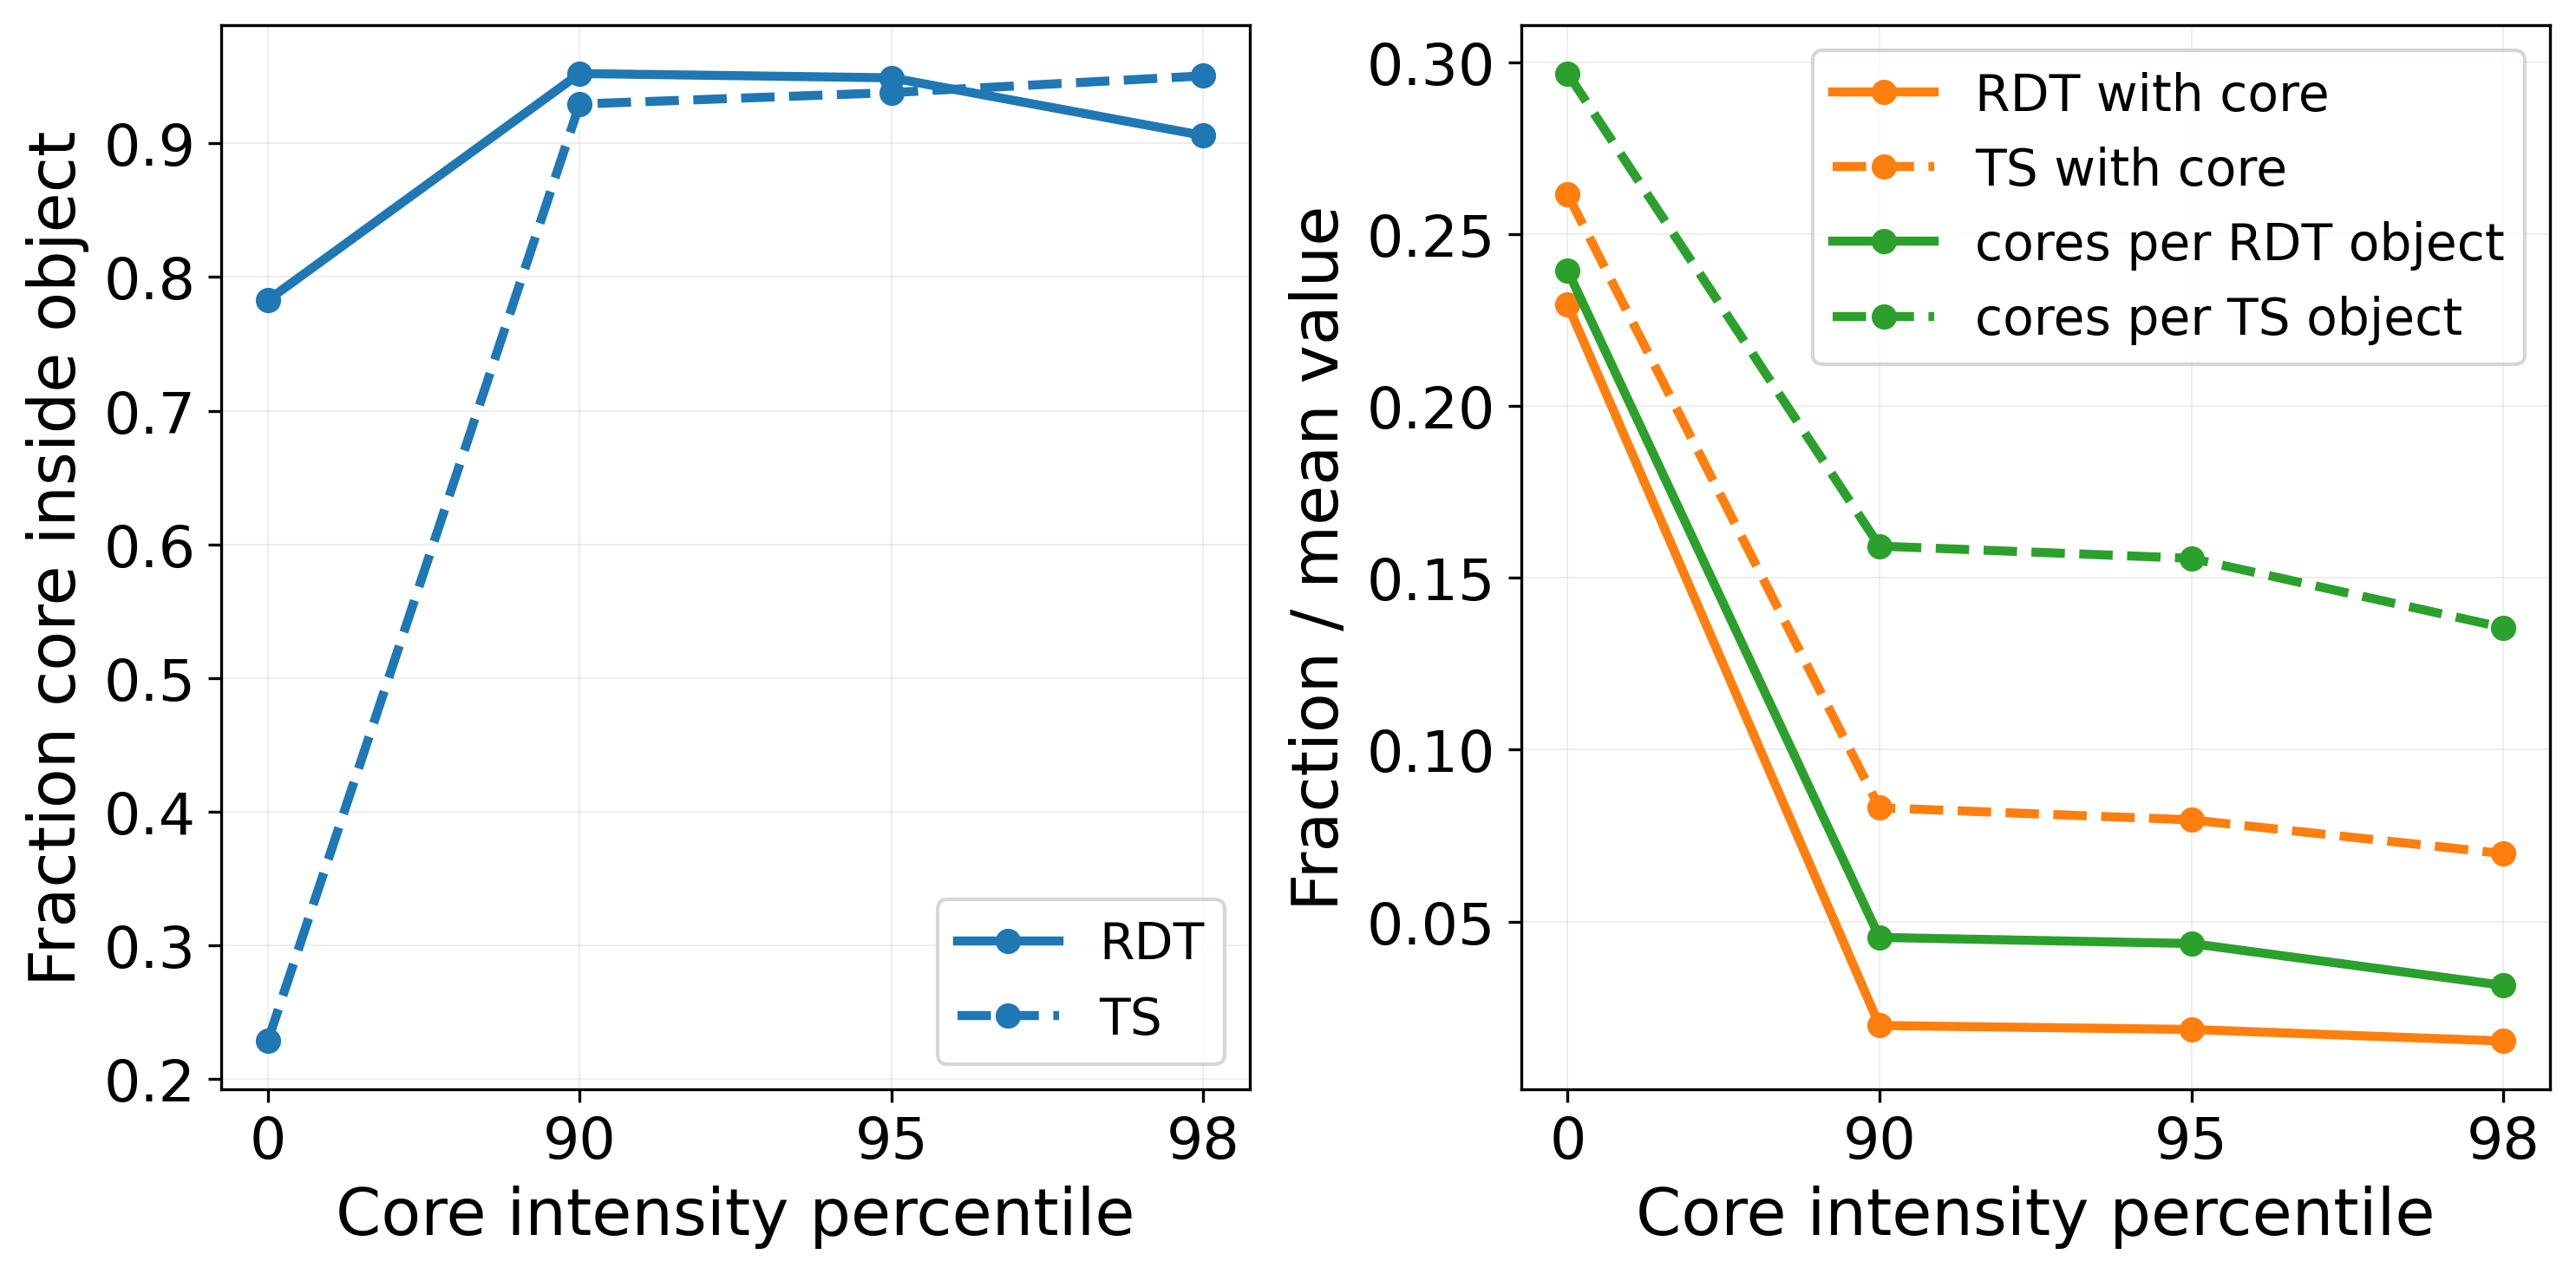

In [3]:
thresholds = ["0", "90", "95", "98"]

fig, axes = plt.subplots(1, 2, figsize=(10,5), dpi=300)

metric_colors = {
    "core_inside": "C0",
    "obj_with_core": "C1",
    "cores_per_obj": "C2"
}

linestyle_map = {
    "rdt": "-",
    "dwd": "--"
}

label_map = {
    "rdt": "RDT",
    "dwd": "TS"
}

handles_panel2 = []

for product in ["rdt", "dwd"]:

    core_inside = []
    obj_with_core = []
    cores_per_obj = []

    for thr in thresholds:

        df = data[product][thr]

        core_inside.append(df[f"fraction_core_inside_{product}"].mean())
        obj_with_core.append(df[f"fraction_{product}_with_core"].mean())
        cores_per_obj.append(df[f"mean_cores_per_{product}"].mean())

    x = np.arange(len(thresholds))

    axes[0].plot(
        x,
        core_inside,
        marker="o",
        linewidth=2.5,
        linestyle=linestyle_map[product],
        color=metric_colors["core_inside"],
        label=f"{label_map[product]}"
    )

    h1 = axes[1].plot(
        x,
        obj_with_core,
        marker="o",
        linewidth=2.5,
        linestyle=linestyle_map[product],
        color=metric_colors["obj_with_core"],
        label=f"{label_map[product]} object"
    )[0]

    h2 = axes[1].plot(
        x,
        cores_per_obj,
        marker="o",
        linewidth=2.5,
        linestyle=linestyle_map[product],
        color=metric_colors["cores_per_obj"],
        label=f"cores per {label_map[product]} object"
    )[0]

    handles_panel2.append((h1, h2))


for ax in axes:

    ax.set_xticks(x)
    ax.set_xticklabels(thresholds)

    ax.tick_params(axis="both", labelsize=16)

    ax.grid(True, linewidth=0.1)


axes[0].set_xlabel("Core intensity percentile", fontsize=18)
axes[0].set_ylabel("Fraction core inside object", fontsize=18)
axes[0].legend(fontsize=14)

axes[1].set_xlabel("Core intensity percentile", fontsize=18)
axes[1].set_ylabel("Fraction / mean value", fontsize=18)

# force legend order
handles = [
    handles_panel2[0][0],
    handles_panel2[1][0],
    handles_panel2[0][1],
    handles_panel2[1][1],
]

labels = [
    "RDT with core",
    "TS with core",
    "cores per RDT object",
    "cores per TS object",
]

axes[1].legend(handles, labels, fontsize=14)

plt.tight_layout()

plt.show()

- cores detect convective intensity

- RDT detects storm objects

- strong convection is a rare subset of storms

Strong convective cores almost always occur inside storms,
but only a small fraction of storms contain strong cores.

cores per object: average number of wavelet cores inside each detected object.

RDT cores per object = mean cores inside an RDT cell